<a href="https://colab.research.google.com/github/misbakhulfajar27-killertheriper/Tugas_2/blob/main/Tugas2_misbakhul_Fajar_047996694.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**<center>$\color{green}{\text{TUGAS 2 : KLASIFIKASI}}$</center>**

> Add blockquote



---


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1
Mulailah memuat semua data yang ada ke sistem.

In [3]:
# Import library (letakkan paling atas)
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Muat data dari kedua sumber
# ...
df1 = pd.read_csv("Data Siswa Periode 1.csv")
df2 = pd.read_csv("Data Siswa Periode 2.csv")
print("Ukuran Periode 1 (baris, kolom):", df1.shape)
print("Ukuran Periode 2 (baris, kolom):", df2.shape)


# 2) Lihat atribut apa saja yang ada dari kedua data tersebut
# ...
print("\nKolom Periode 1:", df1.columns.tolist())
print("\nKolom Periode 2:", df2.columns.tolist())

print("\nHanya ada di Periode 1:", set(df1.columns) - set(df2.columns))
print("Hanya ada di Periode 2:", set(df2.columns) - set(df1.columns))

Ukuran Periode 1 (baris, kolom): (1827, 21)
Ukuran Periode 2 (baris, kolom): (1730, 21)

Kolom Periode 1: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Reguler/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']

Kolom Periode 2: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Siang/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Umur saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']

Hanya ada di Periode 1: {'Usia saat mendaftar', 'Kelas Reguler/Malam'}
Hanya ada di Periode 2: {'Kelas Siang/Mala

##Task 2
Datanya sudah termuat, fitur nya hampir semuanya sama, tetapi ada yang berbeda sehingga perlu dipetakan

In [4]:
# 1) Identifikasi fitur serupa, lakukan penamaan ulang fitur serupa
# ...
df1 = df1.rename(columns={"Usia saat mendaftar": "Usia",
                          "Kelas Reguler/Malam": "Kelas"})

df2 = df2.rename(columns={"Umur saat mendaftar": "Usia",
                          "Kelas Siang/Malam": "Kelas"})

# Cek hasilnya
print("Kolom Periode 1:", df1.columns.tolist())
print("Kolom Periode 2:", df2.columns.tolist())
print("\nNama kolom sama persis?", set(df1.columns) == set(df2.columns))

Kolom Periode 1: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia', 'IP Semester 1', 'IP Semester 2', 'Target']
Kolom Periode 2: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia', 'IP Semester 1', 'IP Semester 2', 'Target']

Nama kolom sama persis? True


##Task 3
Butuh penyatuan data, tapi ternyata ada kodefikasi atribut fitur yang berbeda, harus di samakan

In [5]:
# 1) Lakukan penyamaan kodefikasi atribut
# ...
# mengambil semua kolom bertipe teks, kecuali Target
kolom_kategori = df1.select_dtypes(exclude="number").columns.drop("Target")

# membandingkan nilai unik tiap kolom di kedua data
for k in kolom_kategori:
    u1 = set(df1[k].dropna().unique())
    u2 = set(df2[k].dropna().unique())
    if u1 != u2:
        print(f"[BEDA] {k}")
        print("   Periode 1:", sorted(u1))
        print("   Periode 2:", sorted(u2))
# menganti kode Periode 1 supaya sama dengan Periode 2
df1["Jenis Kelamin"] = df1["Jenis Kelamin"].replace({"Wanita": "Perempuan",
                                                     "Pria": "Laki-laki"})
df1["Kelas"] = df1["Kelas"].replace({"Reguler": "Siang"})

# Cek ulang: harusnya tidak ada lagi perbedaan
for k in kolom_kategori:
    assert set(df1[k].dropna().unique()) == set(df2[k].dropna().unique()), k
print("Semua kodefikasi kategori sudah seragam.")
# 2) Lakukan penyatuan data
# ...
df = pd.concat([df1, df2], ignore_index=True)

print("Ukuran data gabungan:", df.shape)
df.head()


[BEDA] Kelas
   Periode 1: ['Malam', 'Reguler']
   Periode 2: ['Malam', 'Siang']
[BEDA] Jenis Kelamin
   Periode 1: ['Pria', 'Wanita']
   Periode 2: ['Laki-laki', 'Perempuan']
Semua kodefikasi kategori sudah seragam.
Ukuran data gabungan: (3557, 21)


,ID,Status Pernikahan,Program Studi,Kelas,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,Pekerjaan Ayah,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia,IP Semester 1,IP Semester 2,Target
0,2,Belum Menikah,Teknik Industri,Siang,SMA/Sederajat,66.55,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,Lainnya,53.00,Ya,Tidak,Sudah,Laki-laki,Tidak,21,2.48,2.52,Lulus Tepat Waktu
1,3,Belum Menikah,Jurnalistik,Siang,SMA/Sederajat,63.50,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,Pegawai Swasta,58.25,Tidak,Tidak,Sudah,Perempuan,Ya,19,2.86,2.63,Lulus Tepat Waktu
2,4,Belum Menikah,Pertanian,Siang,SMA/Sederajat,62.50,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Wiraswasta,Lainnya,60.75,Ya,Tidak,Sudah,Laki-laki,Tidak,18,2.20,2.07,Lulus Tidak Tepat Waktu
3,5,Belum Menikah,Teknik Mesin,Siang,Perguruan Tinggi,75.00,Pulau Jawa,Lebih dari S1,Lebih dari S1,Pegawai Swasta,Pegawai Swasta,75.00,Tidak,Tidak,Sudah,Perempuan,Tidak,20,2.60,2.40,Lulus Tidak Tepat Waktu
4,10,Belum Menikah,Perbankan,Siang,SMA/Sederajat,65.00,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,Pegawai Negri,64.55,Ya,Tidak,Sudah,Perempuan,Tidak,18,2.61,2.72,Lulus Tepat Waktu


##Task 4
Sekarang kita lakukan analisis atribut untuk setiap fitur nya, mulai dengan penanganan missing/null value

In [6]:
# 1)	Identifikasi dan tangani missing/null value
# ...
# (a) Baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah hapus duplikat:", df.shape)
# (b) Missing value (sel kosong / NaN)
print("\nMissing value per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])
for k in ["Kelas", "Daerah Asal"]:
    modus = df[k].mode()[0]
    print(f"{k}: diisi dengan modus = '{modus}'")
    df[k] = df[k].fillna(modus)
# (c) Nilai tidak valid: usia tidak mungkin negatif
print("\nJumlah usia negatif:", (df["Usia"] < 0).sum())
print(df.loc[df["Usia"] < 0, "Usia"].tolist())

df.loc[df["Usia"] < 0, "Usia"] = np.nan
df["Usia"] = df["Usia"].fillna(df["Usia"].median())

print("\nSisa missing value:", df.isnull().sum().sum())
print("Usia minimum sekarang:", df["Usia"].min())
print("Ukuran data:", df.shape)

Jumlah baris duplikat: 22
Ukuran data setelah hapus duplikat: (3535, 21)

Missing value per kolom:
Kelas          3
Daerah Asal    3
dtype: int64
Kelas: diisi dengan modus = 'Siang'
Daerah Asal: diisi dengan modus = 'Pulau Jawa'

Jumlah usia negatif: 7
[-18, -23, -20, -31, -25, -21, -39]

Sisa missing value: 0
Usia minimum sekarang: 17.0
Ukuran data: (3535, 21)


##Task 5
Untuk bisa melihat bentuk dari data, kita perlu menghitung histogram dari setiap fitur. Dari situ kemudian kita bisa lanjutkan dengan penanganan outlier.

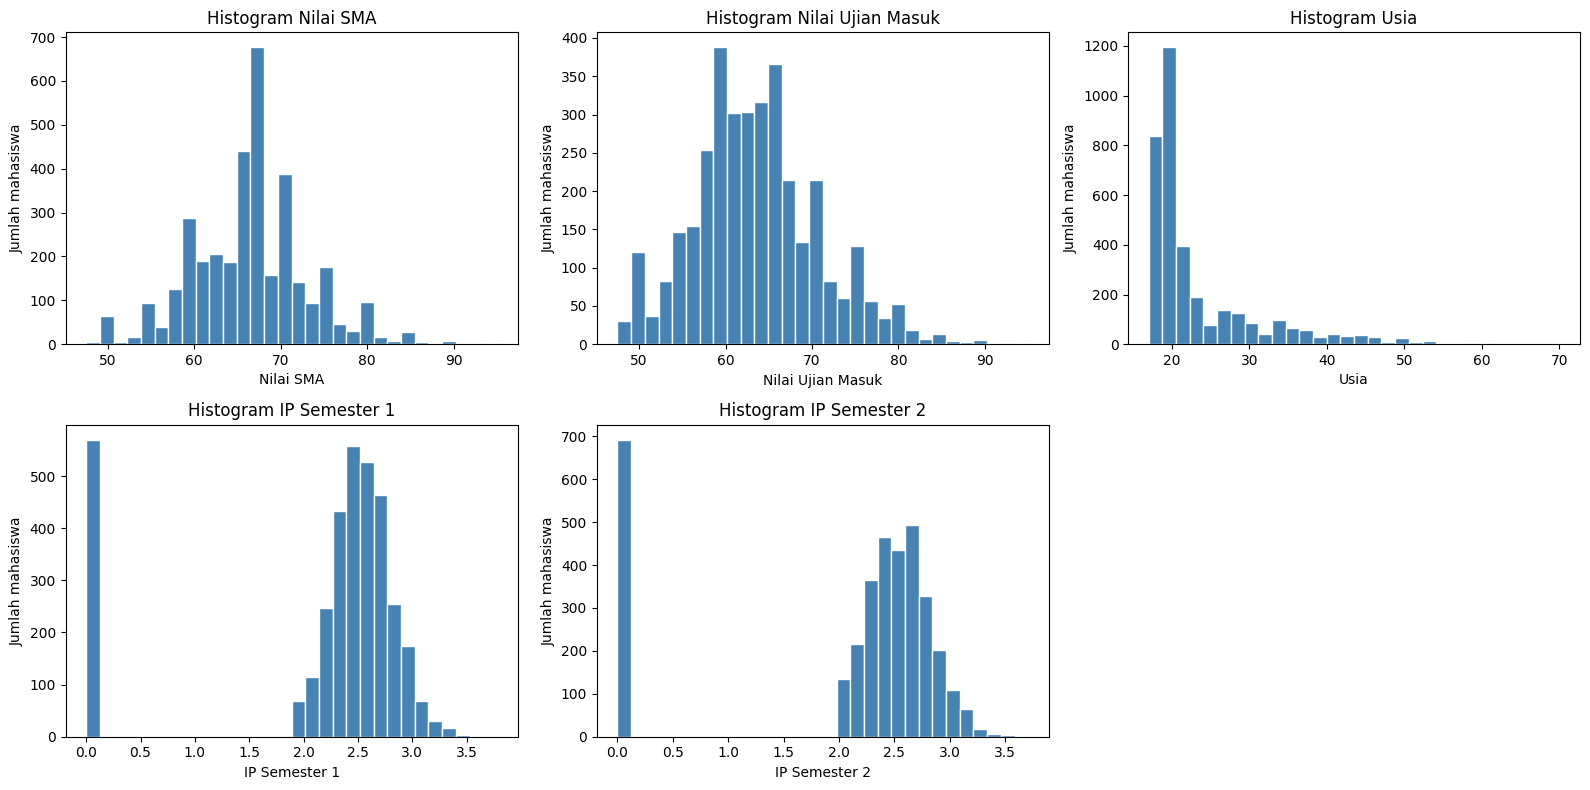

Jumlah fitur kategorikal: 14


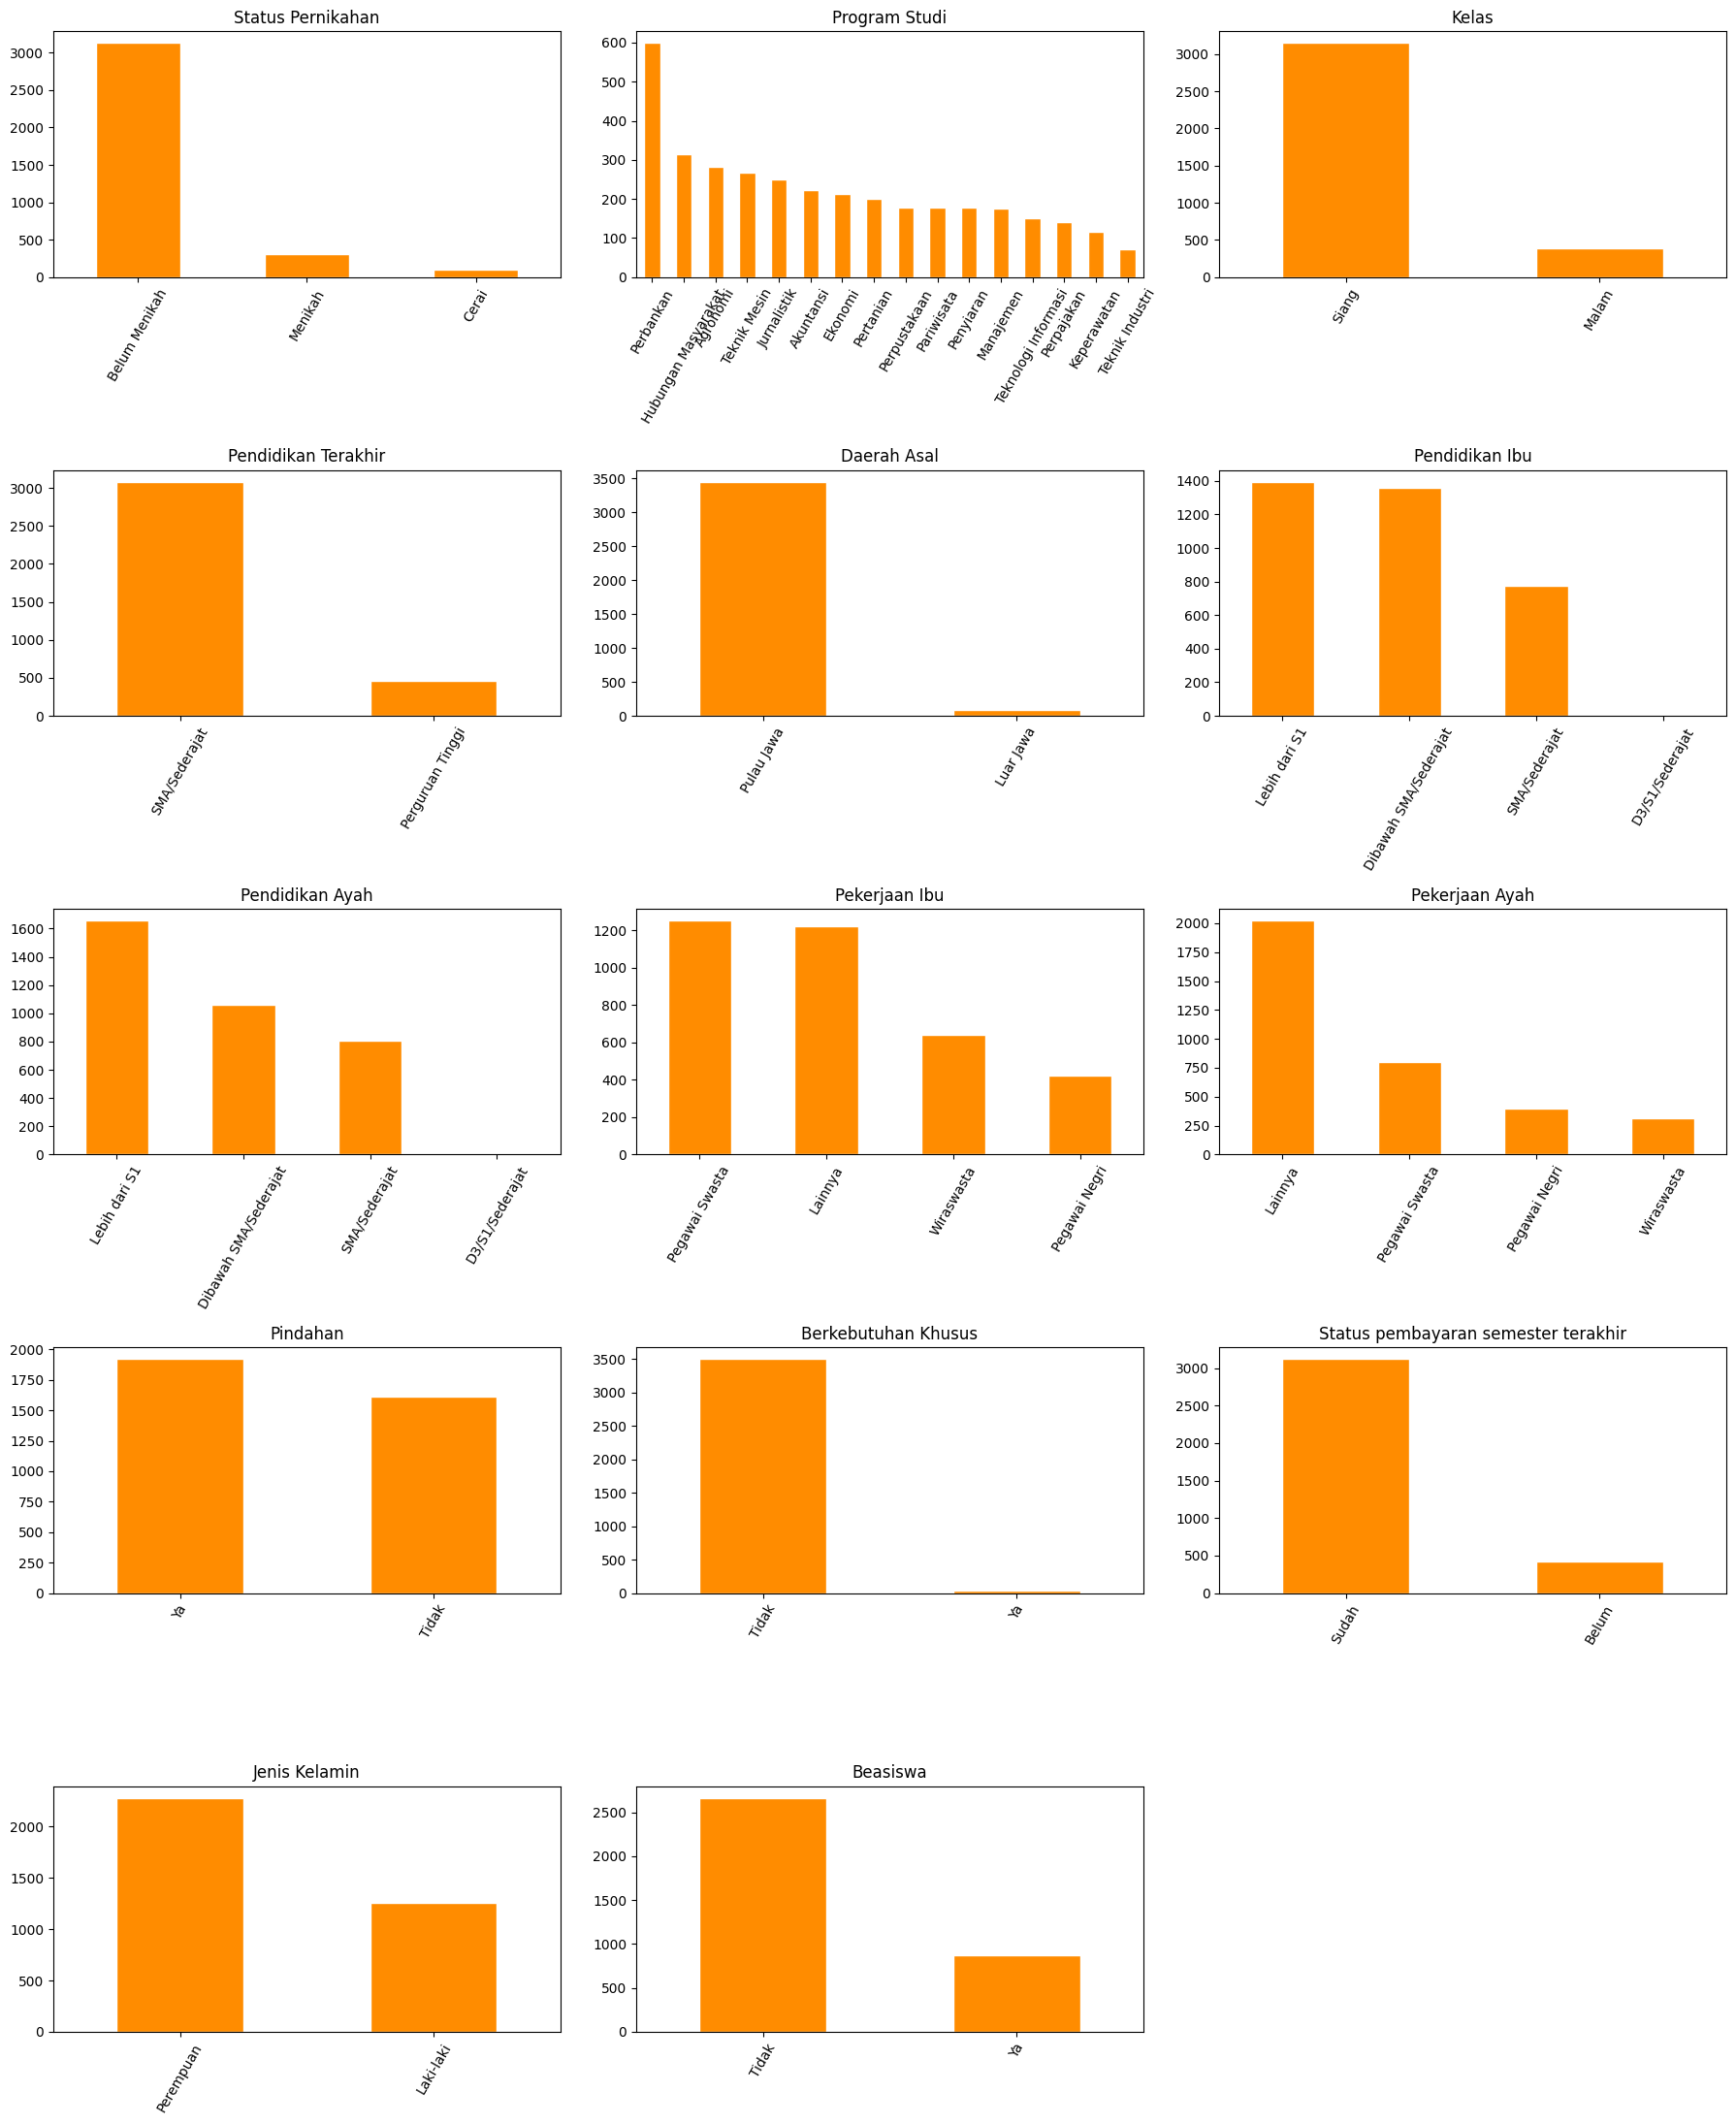

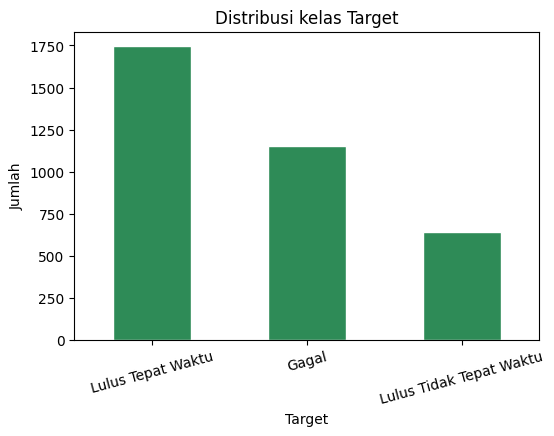

Target
Lulus Tepat Waktu          1745
Gagal                      1150
Lulus Tidak Tepat Waktu     640
Name: count, dtype: int64


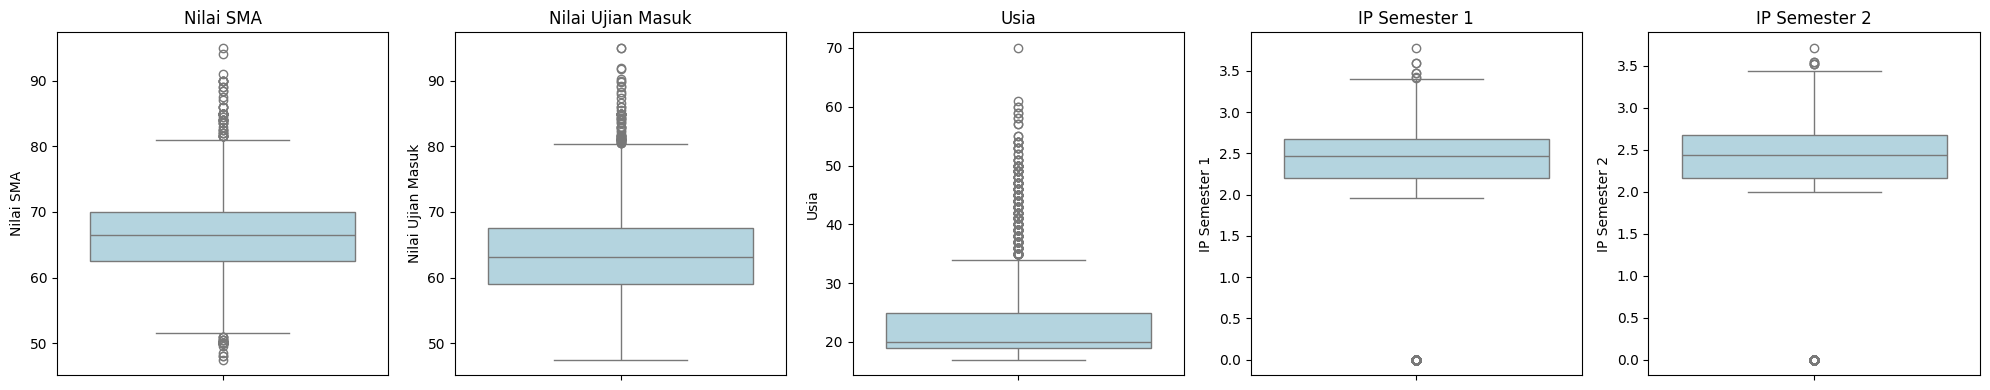

Baris sebelum: 3535 | sesudah: 3328 | dihapus: 207
Target
Lulus Tepat Waktu          1633
Gagal                      1082
Lulus Tidak Tepat Waktu     613
Name: count, dtype: int64


In [7]:
# 1)	Hitung histogram setiap fitur, tampilkan dalam bentuk grafik batang
# ...
kolom_num = ["Nilai SMA", "Nilai Ujian Masuk", "Usia", "IP Semester 1", "IP Semester 2"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, k in zip(axes.ravel(), kolom_num):
    ax.hist(df[k], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"Histogram {k}")
    ax.set_xlabel(k)
    ax.set_ylabel("Jumlah mahasiswa")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()
kolom_kat = [k for k in df.select_dtypes(exclude="number").columns if k != "Target"]
print("Jumlah fitur kategorikal:", len(kolom_kat))

fig, axes = plt.subplots(5, 3, figsize=(18, 22))
for ax, k in zip(axes.ravel(), kolom_kat):
    df[k].value_counts().plot(kind="bar", ax=ax, color="darkorange", edgecolor="white")
    ax.set_title(k)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
for ax in axes.ravel()[len(kolom_kat):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Distribusi kelas Target
df["Target"].value_counts().plot(kind="bar", color="seagreen", edgecolor="white", figsize=(6, 4))
plt.title("Distribusi kelas Target")
plt.ylabel("Jumlah")
plt.xticks(rotation=15)
plt.show()
print(df["Target"].value_counts())
# 2)	Identifikasi outlier dengan boxplot
# ...
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, k in zip(axes, kolom_num):
    sns.boxplot(y=df[k], ax=ax, color="lightblue")
    ax.set_title(k)
plt.tight_layout()
plt.show()
def batas_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

ringkas = []
for k in kolom_num:
    lo, hi = batas_iqr(df[k])
    jumlah = int(((df[k] < lo) | (df[k] > hi)).sum())
    ringkas.append([k, round(lo, 2), round(hi, 2), jumlah])

pd.DataFrame(ringkas, columns=["Fitur", "Batas bawah", "Batas atas", "Jumlah outlier"])
# 3)	Hapus outlier dari data
# ...
HAPUS_OUTLIER_USIA = False   # ubah ke True jika dosen meminta Usia juga dibersihkan

fitur_hapus = ["Nilai SMA", "Nilai Ujian Masuk"] + (["Usia"] if HAPUS_OUTLIER_USIA else [])

sebelum = len(df)
for k in fitur_hapus:
    lo, hi = batas_iqr(df[k])
    df = df[(df[k] >= lo) & (df[k] <= hi)]
df = df.reset_index(drop=True)

print(f"Baris sebelum: {sebelum} | sesudah: {len(df)} | dihapus: {sebelum - len(df)}")
print(df["Target"].value_counts())

##Task 6
Agar nantinya kita bisa mendapatkan fitur yang relevan, sebaiknya kita melihat hubungan setiap fitur dengan kelas target.

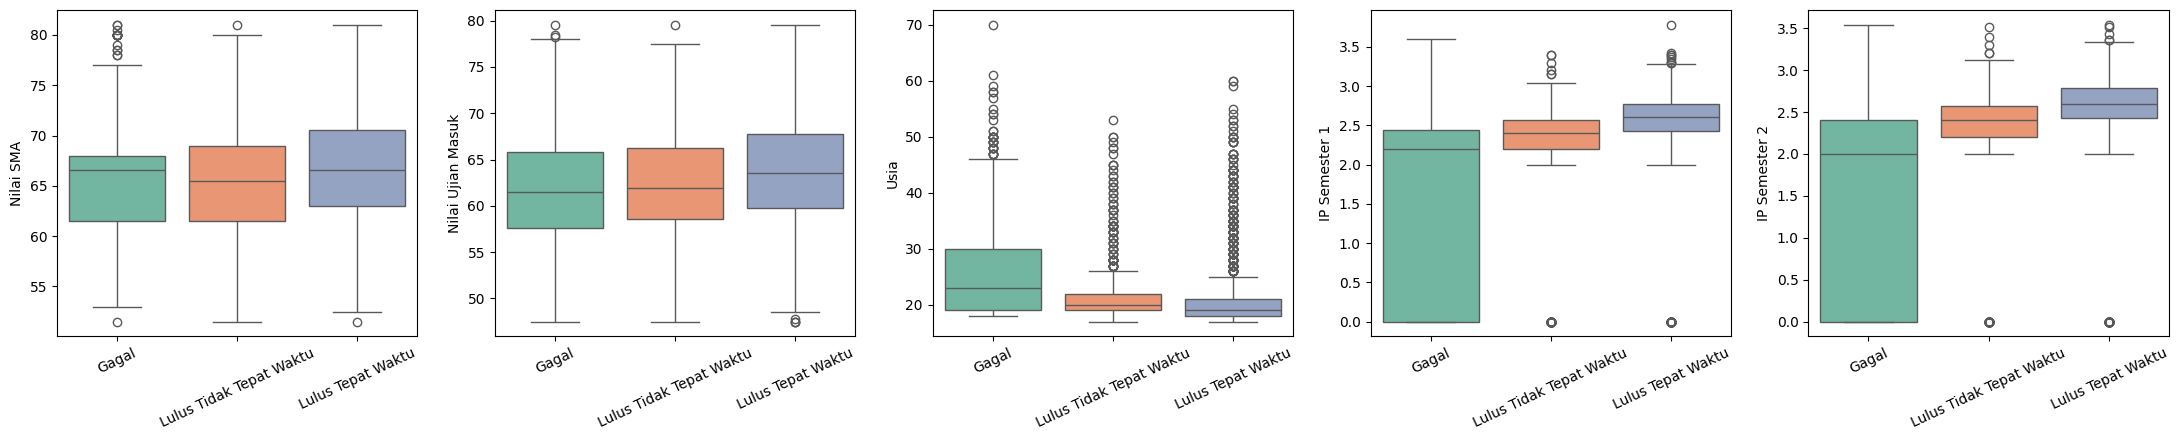

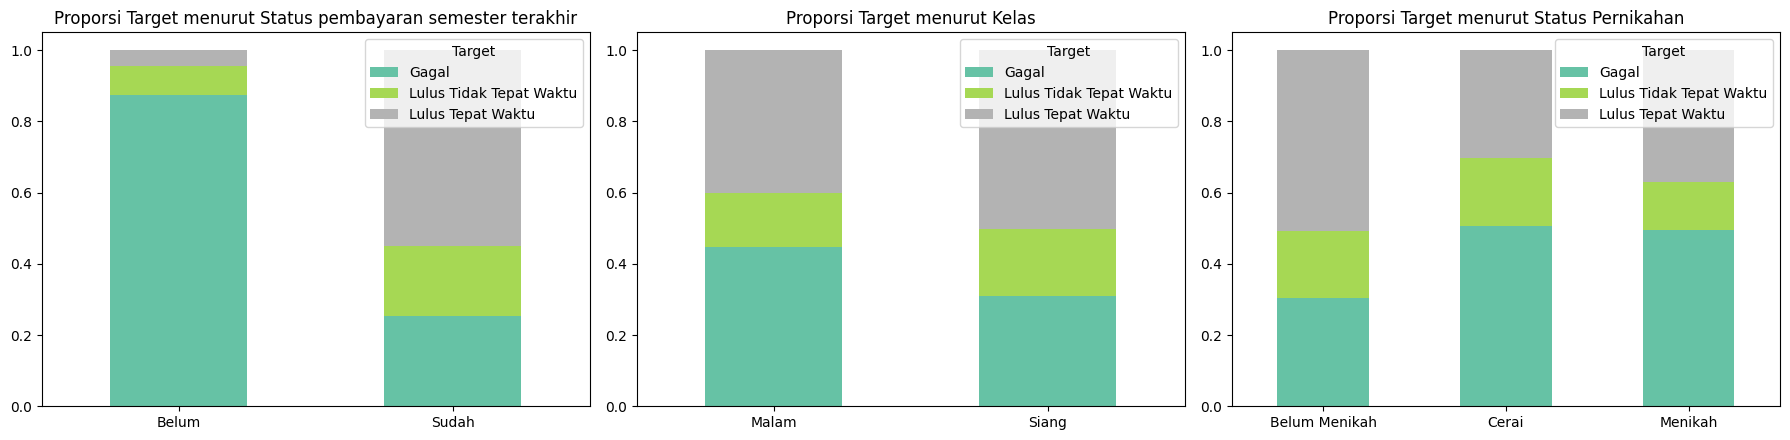

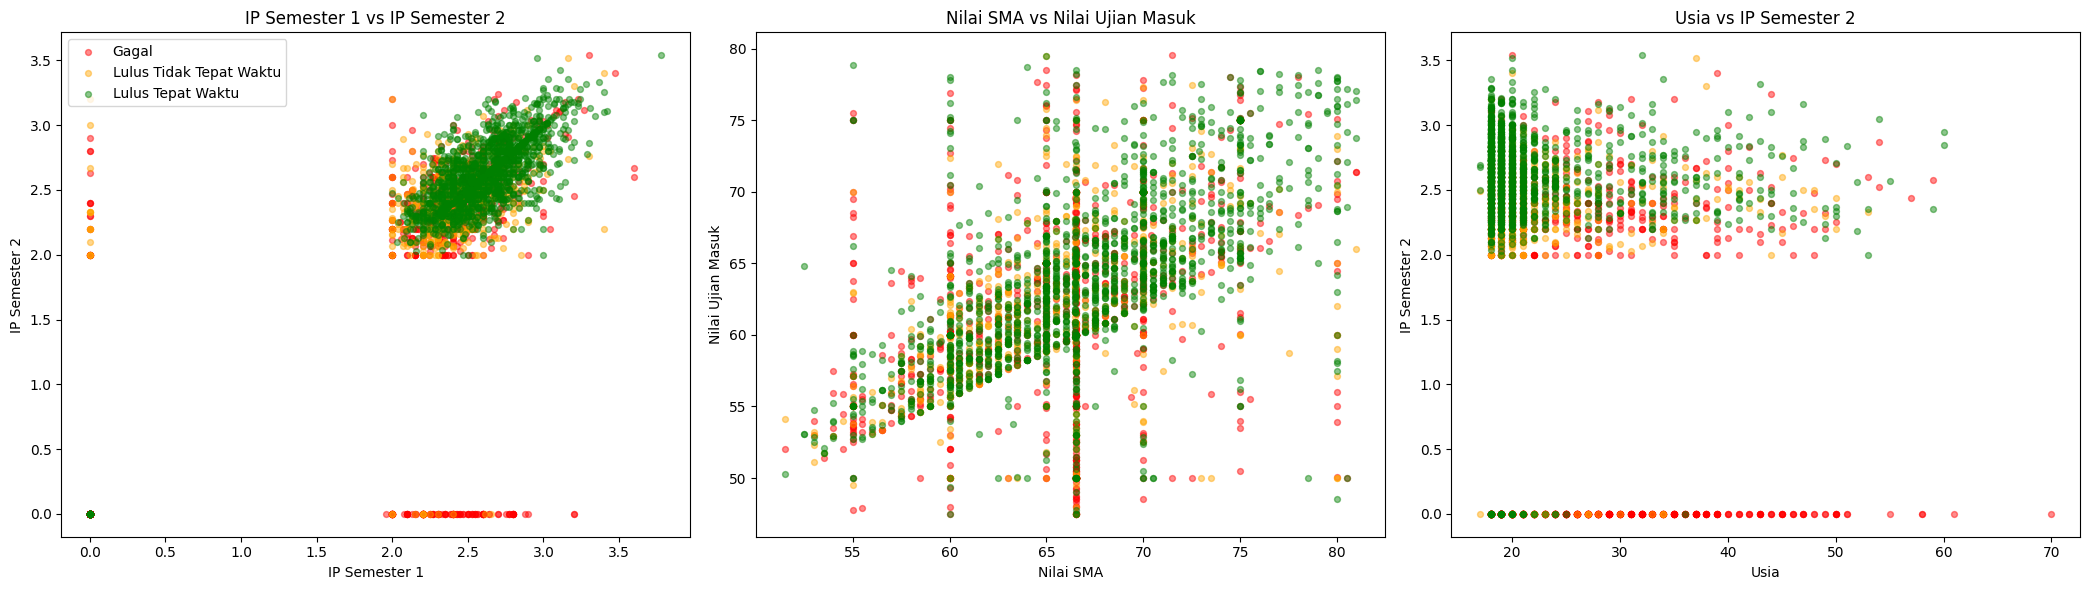

In [8]:
from scipy.stats import f_oneway, chi2_contingency

urutan_target = ["Gagal", "Lulus Tidak Tepat Waktu", "Lulus Tepat Waktu"]
# 1)	Lakukan analisis bivariate
# ...
# (a) Rata-rata tiap fitur numerik per kelas Target
df.groupby("Target")[kolom_num].mean().loc[urutan_target].round(2)
hasil = []
for k in kolom_num:
    grup = [df.loc[df["Target"] == t, k] for t in urutan_target]
    f, p = f_oneway(*grup)
    hasil.append([k, round(f, 2), p])

pd.DataFrame(hasil, columns=["Fitur", "F", "p-value"])
# (b) Kategorikal vs Target
hasil = []
for k in kolom_kat:
    tab = pd.crosstab(df[k], df["Target"])
    chi2, p, _, _ = chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    hasil.append([k, round(chi2, 2), p, round(v, 3)])

tabel_kat = pd.DataFrame(hasil, columns=["Fitur", "Chi2", "p-value", "Cramer's V"])
tabel_kat.sort_values("Cramer's V", ascending=False)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, k in zip(axes, kolom_num):
    sns.boxplot(data=df, x="Target", y=k, order=urutan_target, ax=ax, palette="Set2")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, k in zip(axes, ["Status pembayaran semester terakhir", "Kelas", "Status Pernikahan"]):
    pd.crosstab(df[k], df["Target"], normalize="index")[urutan_target].plot(
        kind="bar", stacked=True, ax=ax, colormap="Set2")
    ax.set_title(f"Proporsi Target menurut {k}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
# 2)	Plot kedalam grafik sebaran (scatter)
# ...
# 2) Plot kedalam grafik sebaran (scatter)
warna = {"Gagal": "red", "Lulus Tidak Tepat Waktu": "orange", "Lulus Tepat Waktu": "green"}
pasangan = [("IP Semester 1", "IP Semester 2"),
            ("Nilai SMA", "Nilai Ujian Masuk"),
            ("Usia", "IP Semester 2")]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (x, y) in zip(axes, pasangan):
    for t in urutan_target:
        sub = df[df["Target"] == t]
        ax.scatter(sub[x], sub[y], c=warna[t], label=t, alpha=0.45, s=18)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")
axes[0].legend()
plt.tight_layout()
plt.show()

##Task 7
Oke, sepertinya sudah siap, tapi kok jumlah data per-kelas nya tidak seimbang ya, ada beberapa algoritma yang akan terpengaruh dengan kondisi ini, kita akan gunakan algoritma **$\color{orange}{\text{(Nama Algoritma)}}$** untuk menyelesaikan masalah ini, jadi kita **$\color{orange}{\text{(akan/tidak akan)}}$** melakukan proses augmentasi data karena **$\color{orange}{\text{(Alasan melakukan augmentasi/tidak)}}$**

In [9]:
# 1)	Augmentasi data untuk balancing kelas (Optional)
# ...
dist = df["Target"].value_counts()
print(dist)

print("\nProporsi (%):")
print((dist / dist.sum() * 100).round(1))

print(f"\nRasio kelas terbesar : terkecil = {dist.max() / dist.min():.2f} : 1")

Target
Lulus Tepat Waktu          1633
Gagal                      1082
Lulus Tidak Tepat Waktu     613
Name: count, dtype: int64

Proporsi (%):
Target
Lulus Tepat Waktu          49.1
Gagal                      32.5
Lulus Tidak Tepat Waktu    18.4
Name: count, dtype: float64

Rasio kelas terbesar : terkecil = 2.66 : 1


Selanjutnya datanya perlu kita bagi dengan ratio **$\color{orange}{\text{(.?.)}}$** : **$\color{orange}{\text{(.?.)}}$**
Dimana **$\color{orange}{\text{(.?.)}}$** adalah data training
Dan **$\color{orange}{\text{(.?.)}}$** adalah data testing


In [10]:
# ---- Persiapan fitur ----

# Target diubah jadi angka
y = df["Target"].map({"Gagal": 0,
                      "Lulus Tidak Tepat Waktu": 1,
                      "Lulus Tepat Waktu": 2})
nama_kelas = ["Gagal", "Lulus Tidak Tepat Waktu", "Lulus Tepat Waktu"]

# Fitur: semua kolom kecuali ID dan Target
X = df.drop(columns=["ID", "Target"])

# Pendidikan Ibu/Ayah: kategori berurutan
urut_pend = {"Dibawah SMA/Sederajat": 0, "SMA/Sederajat": 1,
             "D3/S1/Sederajat": 2, "Lebih dari S1": 3}
for k in ["Pendidikan Ibu", "Pendidikan Ayah"]:
    X[k] = X[k].map(urut_pend)

# Kolom dua pilihan -> 1 / 0
for k in ["Pindahan", "Berkebutuhan Khusus", "Beasiswa"]:
    X[k] = X[k].map({"Ya": 1, "Tidak": 0})
X["Status pembayaran semester terakhir"] = X["Status pembayaran semester terakhir"].map({"Sudah": 1, "Belum": 0})
X["Pendidikan Terakhir"] = X["Pendidikan Terakhir"].map({"SMA/Sederajat": 0, "Perguruan Tinggi": 1})

# Kategori tanpa urutan -> One-Hot Encoding
X = pd.get_dummies(X, dtype=int)

print("Bentuk fitur akhir:", X.shape)
# 1)	Lakukan pembagian data training dan testing
# ...
# 1) Lakukan pembagian data training dan testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Data training:", X_train.shape, "| Data testing:", X_test.shape)

print("\nProporsi kelas training:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Proporsi kelas testing:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Bentuk fitur akhir: (3328, 45)
Data training: (2662, 45) | Data testing: (666, 45)

Proporsi kelas training:
Target
0    0.325
1    0.184
2    0.491
Name: proportion, dtype: float64
Proporsi kelas testing:
Target
0    0.324
1    0.185
2    0.491
Name: proportion, dtype: float64


##Task 8
Sekarang kita mulai training nya

In [11]:
# 1)	Lakukan proses training dengan algoritma yang telah dipilih
# ...
# 1) Lakukan proses training dengan algoritma yang telah dipilih
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Model A: tanpa batasan (pembanding)
rf_polos = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=42, n_jobs=-1)
rf_polos.fit(X_train, y_train)
print("Model A (tanpa batasan) | akurasi train:",
      round(accuracy_score(y_train, rf_polos.predict(X_train)), 3),
      "| akurasi test:",
      round(accuracy_score(y_test, rf_polos.predict(X_test)), 3))

# Model B: dibatasi (mencegah overfitting)
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                            class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("Model B (dibatasi)      | akurasi train:",
      round(accuracy_score(y_train, rf.predict(X_train)), 3),
      "| akurasi test:",
      round(accuracy_score(y_test, rf.predict(X_test)), 3))

# 2)	Lakukan evaluasi model dengan K-fold
# ...
# 2) Lakukan evaluasi model dengan K-fold
from sklearn.model_selection import StratifiedKFold, cross_val_score

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nama, model in [("Model A (tanpa batasan)", rf_polos), ("Model B (dibatasi)", rf)]:
    acc = cross_val_score(model, X_train, y_train, cv=kf, scoring="accuracy")
    f1m = cross_val_score(model, X_train, y_train, cv=kf, scoring="f1_macro")
    print(nama)
    print("   Akurasi tiap fold :", acc.round(3), "| rata-rata:", round(acc.mean(), 3), "+/-", round(acc.std(), 3))
    print("   F1-macro tiap fold:", f1m.round(3), "| rata-rata:", round(f1m.mean(), 3), "\n")

Model A (tanpa batasan) | akurasi train: 1.0 | akurasi test: 0.73
Model B (dibatasi)      | akurasi train: 0.758 | akurasi test: 0.691
Model A (tanpa batasan)
   Akurasi tiap fold : [0.709 0.745 0.724 0.707 0.697] | rata-rata: 0.716 +/- 0.017
   F1-macro tiap fold: [0.608 0.628 0.619 0.563 0.594] | rata-rata: 0.602 

Model B (dibatasi)
   Akurasi tiap fold : [0.659 0.705 0.692 0.692 0.641] | rata-rata: 0.678 +/- 0.024
   F1-macro tiap fold: [0.616 0.656 0.643 0.645 0.606] | rata-rata: 0.633 



#Task 9
Training sudah selesai dan model sudah diketahui, kita uji hasilnya dengan data testing untuk melihat kemungkinan overfitting dan underfitting, sekaligus menghitung kualitas model dengan matrik pengukuran

In [12]:
# 1)	Evaluasi dengan data testing
# ...
y_pred_train = rf.predict(X_train)
y_pred = rf.predict(X_test)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred)

print(f"Akurasi training: {acc_train:.3f}")
print(f"Akurasi testing : {acc_test:.3f}")
print(f"Selisih (gap)   : {acc_train - acc_test:.3f}")

# 2)	Hitung dengan matrik pengukuran
# ...
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

print(classification_report(y_test, y_pred, target_names=nama_kelas, digits=3))

print("Precision macro:", round(precision_score(y_test, y_pred, average="macro"), 3))
print("Recall macro   :", round(recall_score(y_test, y_pred, average="macro"), 3))
print("F1-score macro :", round(f1_score(y_test, y_pred, average="macro"), 3))

Akurasi training: 0.758
Akurasi testing : 0.691
Selisih (gap)   : 0.067
                         precision    recall  f1-score   support

                  Gagal      0.801     0.708     0.752       216
Lulus Tidak Tepat Waktu      0.366     0.488     0.418       123
      Lulus Tepat Waktu      0.794     0.755     0.774       327

               accuracy                          0.691       666
              macro avg      0.654     0.650     0.648       666
           weighted avg      0.717     0.691     0.701       666

Precision macro: 0.654
Recall macro   : 0.65
F1-score macro : 0.648


##Task 10
Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa

**$\color{orange}{\text{(Lakukan analisis hasil )}}$**

Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa:

1. Kualitas model. Model Random Forest dengan class_weight='balanced' (max_depth=8, min_samples_leaf=5) mencapai akurasi 69,1% pada data testing, dengan precision, recall, dan F1-score macro sekitar 0,65. Hasil K-fold 5 lipat pada data training konsisten (akurasi rata-rata 67,8% dan F1-macro 0,633), sehingga model dapat dikatakan stabil.

2. Overfitting dan underfitting. Akurasi training 75,8% dan akurasi testing 69,1%, selisihnya 6,7 poin. Selisih ini tergolong kecil sampai sedang, jadi model tidak mengalami overfitting berat. Model juga tidak underfitting karena akurasinya jauh di atas tebakan kelas terbanyak (49,1%). Sebagai pembanding, model tanpa batasan mengalami overfitting (akurasi training 100% dan testing 73%), sehingga pembatasan kompleksitas pohon terbukti diperlukan.

3. Kinerja per kelas. Kelas Gagal terdeteksi dengan baik (precision 0,80, recall 0,71; 153 dari 216 mahasiswa yang gagal berhasil dikenali). Kelas Lulus Tepat Waktu juga baik (F1 0,77). Kelas Lulus Tidak Tepat Waktu paling lemah (F1 0,42), karena posisinya berada di antara dua kelas lain sehingga banyak tertukar: 23 ditebak Gagal dan 40 ditebak Lulus Tepat Waktu. Hal ini sejalan dengan scatter plot pada Task 6, di mana titik kelas ini bercampur dengan kelas lain. Model jarang salah pada dua kelas ekstrem (hanya 15 mahasiswa Lulus Tepat Waktu yang ditebak Gagal).

4. Fitur yang berpengaruh. Fitur terpenting adalah IP Semester 2, IP Semester 1, status pembayaran semester terakhir, usia, dan beasiswa. Ini konsisten dengan analisis bivariate di Task 6. Artinya risiko kegagalan sudah dapat dikenali sejak dua semester pertama, terutama dari IP yang bernilai 0, dari belum dibayarnya biaya semester, dan dari usia mahasiswa yang lebih tinggi.

5. Manfaat dan keterbatasan. Model layak dipakai sebagai sistem peringatan dini bagi wali akademik: mahasiswa yang diprediksi Gagal dapat diprioritaskan untuk konseling. Namun prediksi kelas Lulus Tidak Tepat Waktu belum andal, sehingga hasil model sebaiknya dipakai sebagai petunjuk, bukan keputusan akhir. Perbaikan yang dapat dicoba: hyperparameter tuning (misalnya GridSearchCV), algoritma lain seperti Gradient Boosting, penambahan fitur perilaku belajar, atau menyederhanakan target menjadi dua kelas (berisiko dan tidak berisiko).